In [1]:
print("Hello sir")

Hello sir


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [3]:
import pandas as pd


df = pd.read_excel("D:\Customer_churn_project\Telco_customer_churn.xlsx")
df.shape
df.head(5)

<>:4: SyntaxWarning: "\C" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\C"? A raw string is also an option.
<>:4: SyntaxWarning: "\C" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\C"? A raw string is also an option.
C:\Users\gagen\AppData\Local\Temp\ipykernel_21112\2539915026.py:4: SyntaxWarning: "\C" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\C"? A raw string is also an option.
  df = pd.read_excel("D:\Customer_churn_project\Telco_customer_churn.xlsx")


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [4]:
numeric_cols = df.select_dtypes(include=["number"]).columns
categorical_cols = df.select_dtypes(include=["object", "category", "bool"]).columns

print("Numerical columns:")
print(numeric_cols.tolist())

print("\nCategorical columns:")
print(categorical_cols.tolist())

Numerical columns:
['Count', 'Zip Code', 'Latitude', 'Longitude', 'Tenure Months', 'Monthly Charges', 'Churn Value', 'Churn Score', 'CLTV']

Categorical columns:
['CustomerID', 'Country', 'State', 'City', 'Lat Long', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Total Charges', 'Churn Label', 'Churn Reason']


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

In [6]:
df.describe()

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Churn Value,Churn Score,CLTV
count,7043.0,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,1.0,93521.964646,36.282441,-119.798880,32.371149,64.761692,0.265370,58.699418,4400.295755
std,0.0,1865.794555,2.455723,2.157889,24.559481,30.090047,0.441561,21.525131,1183.057152
min,1.0,90001.000000,32.555828,-124.301372,0.000000,18.250000,0.000000,5.000000,2003.000000
25%,1.0,92102.000000,34.030915,-121.815412,9.000000,35.500000,0.000000,40.000000,3469.000000
50%,1.0,93552.000000,36.391777,-119.730885,29.000000,70.350000,0.000000,61.000000,4527.000000
75%,1.0,95351.000000,38.224869,-118.043237,55.000000,89.850000,1.000000,75.000000,5380.500000
max,1.0,96161.000000,41.962127,-114.192901,72.000000,118.750000,1.000000,100.000000,6500.000000


In [7]:

churned = (df["Churn Value"].sum()/(df["Churn Value"].value_counts()[0]+df["Churn Value"].value_counts()[1]))*100
print(f"Percentage of people churned: {churned:.2f} %")

Percentage of people churned: 26.54 %


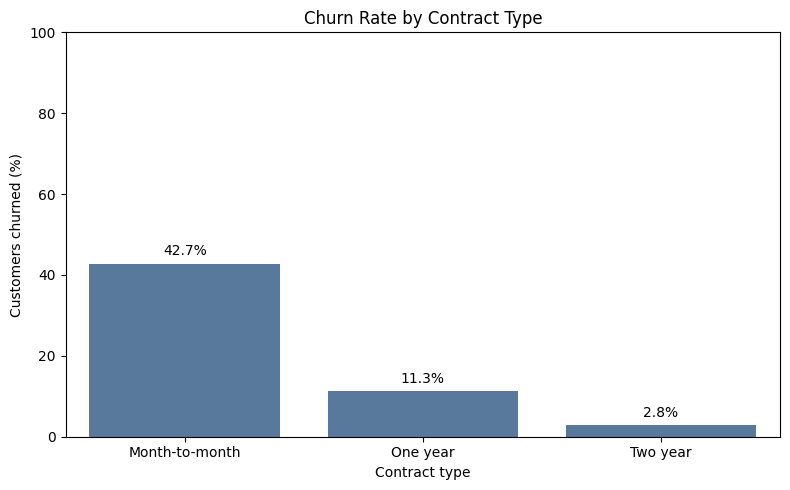

In [8]:

# Calculate the percentage of customers who churned in each contract group
churn_rate = (
    df.groupby("Contract")["Churn Value"]
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    x=churn_rate.index,
    y=churn_rate.values,
    color="#4C78A8"
)

ax.set(
    title="Churn Rate by Contract Type",
    xlabel="Contract type",
    ylabel="Customers churned (%)"
)
ax.set_ylim(0, 100)

# Add the churn rate above each bar
for bar, rate in zip(ax.patches, churn_rate.values):
    ax.annotate(
        f"{rate:.1f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        xytext=(0, 4),
        textcoords="offset points"
    )

plt.tight_layout()
plt.show()

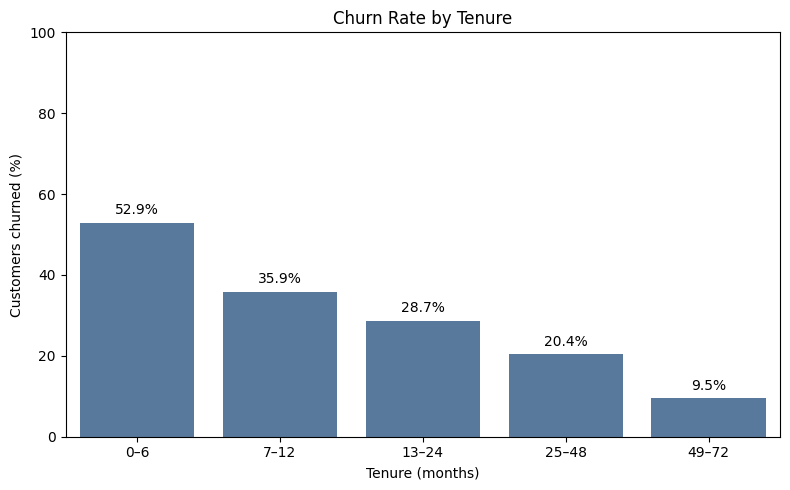

In [9]:
# Group customers into tenure bands
bins = [0, 6, 12, 24, 48, 72]
labels = ["0–6", "7–12", "13–24", "25–48", "49–72"]
df["Tenure Band"] = pd.cut(
    df["Tenure Months"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Mean of Churn Value (1 = churned) gives the churn rate
churn_rate = (
    df.groupby("Tenure Band", observed=False)["Churn Value"]
      .mean()
      .mul(100)
)

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=churn_rate.index, y=churn_rate.values, color="#4C78A8")

ax.set(
    title="Churn Rate by Tenure",
    xlabel="Tenure (months)",
    ylabel="Customers churned (%)"
)
ax.set_ylim(0, 100)

for bar, rate in zip(ax.patches, churn_rate.values):
    ax.annotate(
        f"{rate:.1f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        xytext=(0, 4),
        textcoords="offset points"
    )

plt.tight_layout()
plt.show()

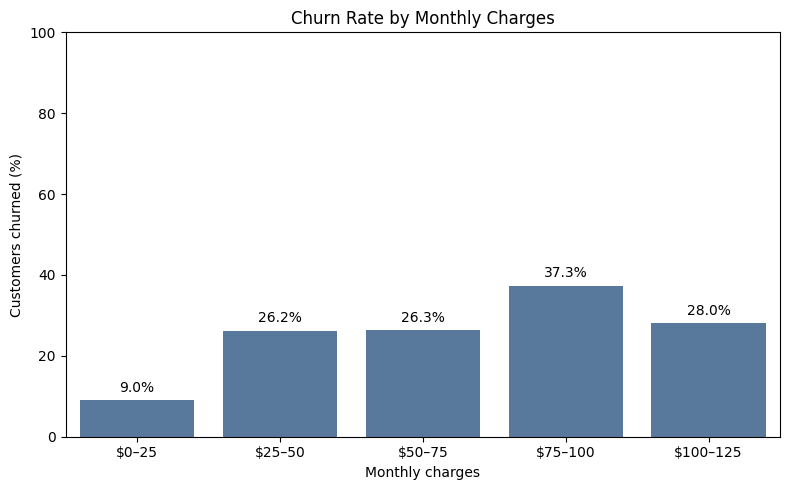

In [10]:
bins = [0, 25, 50, 75, 100, 125]
labels = ["$0–25", "$25–50", "$50–75", "$75–100", "$100–125"]

df["Monthly Charges Band"] = pd.cut(
    df["Monthly Charges"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Since Churn Value is 1 for churned and 0 for retained,
# its mean gives the churn rate in each band.
churn_rate = (
    df.groupby("Monthly Charges Band", observed=False)["Churn Value"]
      .mean()
      .mul(100)
)

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=churn_rate.index, y=churn_rate.values, color="#4C78A8")

ax.set(
    title="Churn Rate by Monthly Charges",
    xlabel="Monthly charges",
    ylabel="Customers churned (%)"
)
ax.set_ylim(0, 100)

for bar, rate in zip(ax.patches, churn_rate.values):
    ax.annotate(
        f"{rate:.1f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        xytext=(0, 4),
        textcoords="offset points"
    )

plt.tight_layout()
plt.show()

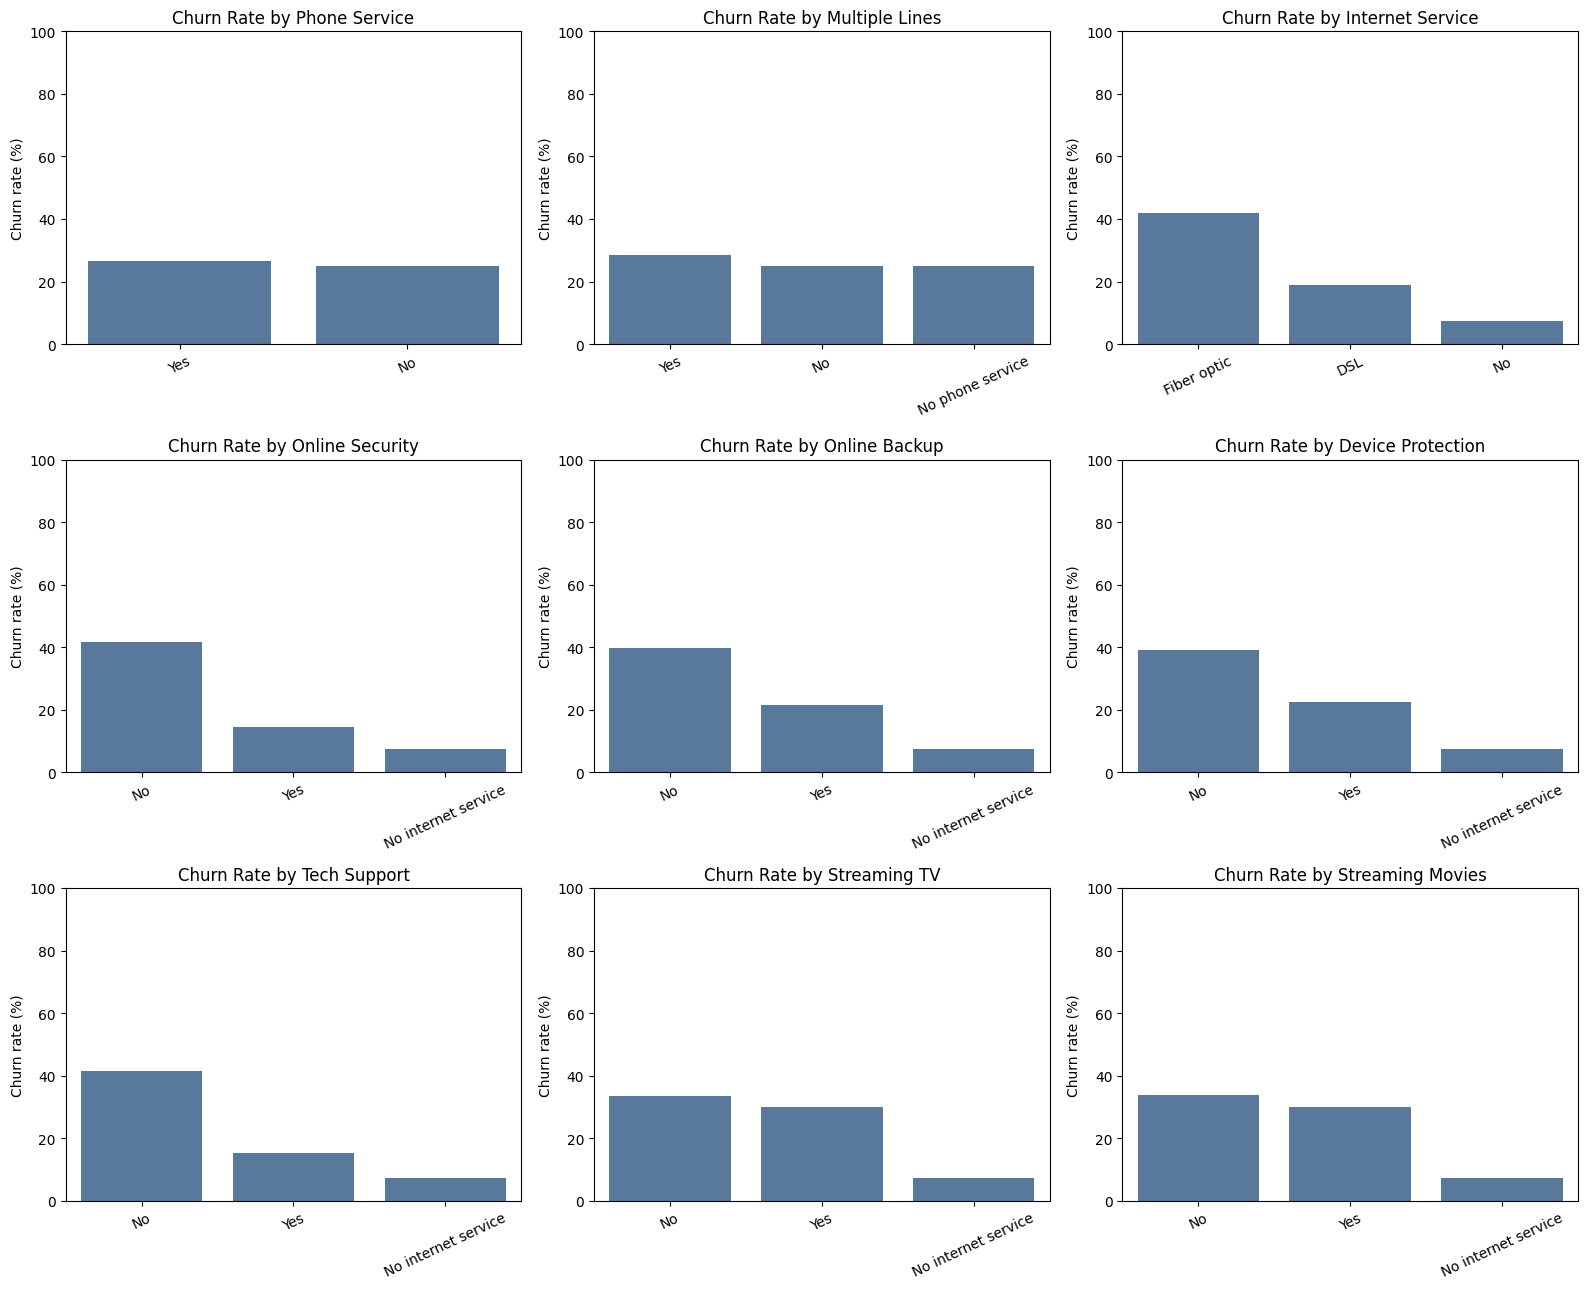

In [11]:
df = pd.read_excel(r"D:\Customer_churn_project\Telco_customer_churn.xlsx")

service_columns = [
    "Phone Service",
    "Multiple Lines",
    "Internet Service",
    "Online Security",
    "Online Backup",
    "Device Protection",
    "Tech Support",
    "Streaming TV",
    "Streaming Movies"
]

fig, axes = plt.subplots(3, 3, figsize=(16, 13))
axes = axes.flatten()

for ax, column in zip(axes, service_columns):
    rates = (
        df.groupby(column, dropna=False)["Churn Value"]
          .mean()
          .mul(100)
          .sort_values(ascending=False)
    )

    sns.barplot(x=rates.index.astype(str), y=rates.values, ax=ax, color="#4C78A8")
    ax.set_title(f"Churn Rate by {column}")
    ax.set_xlabel("")
    ax.set_ylabel("Churn rate (%)")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

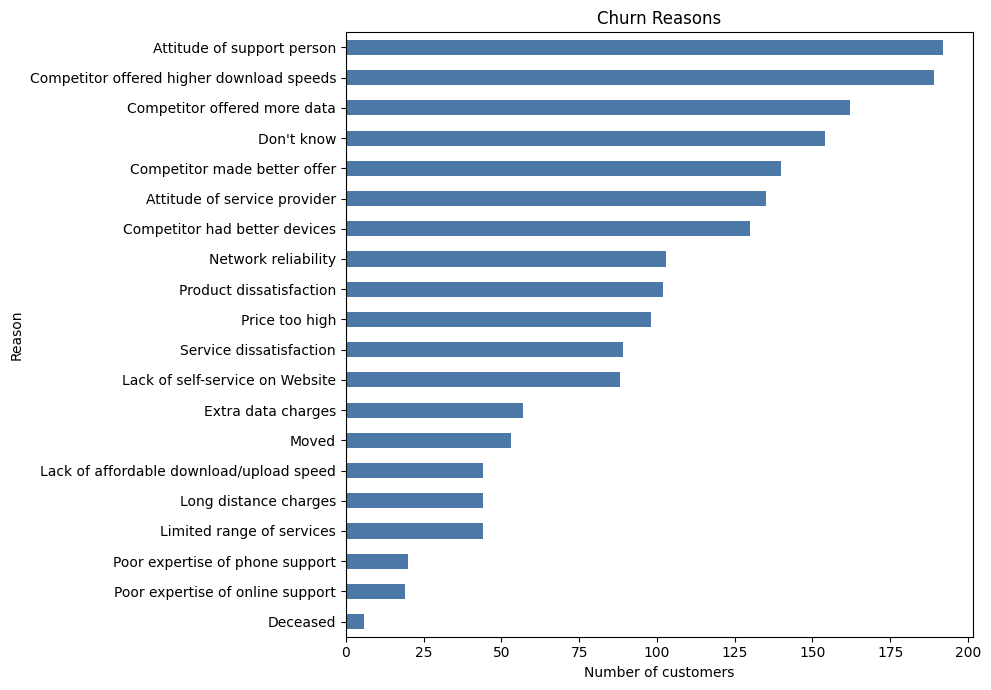

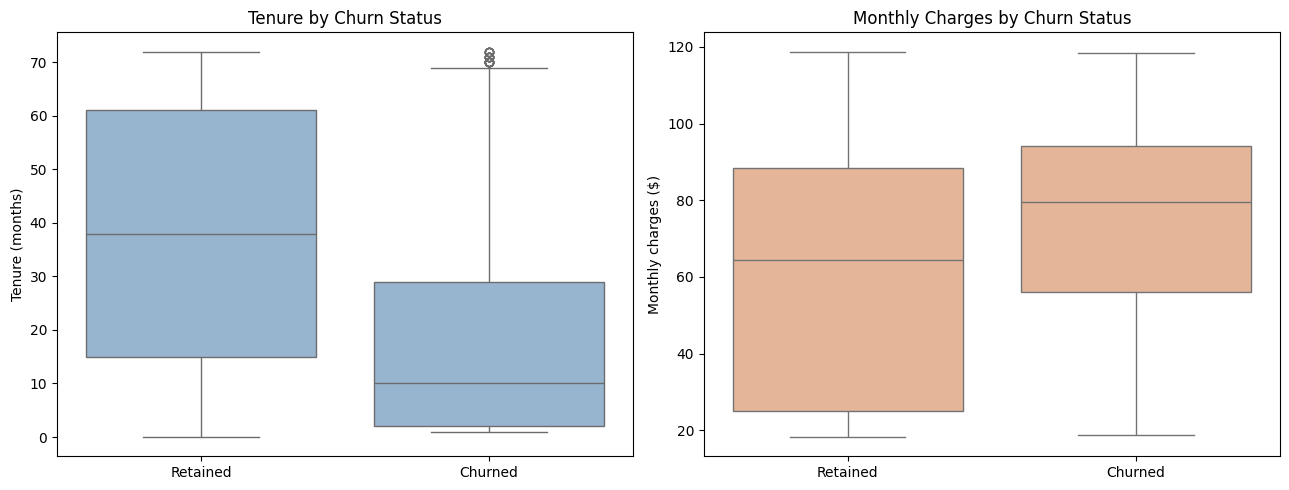

In [12]:
# Use readable labels for churn status
df["Churn Status"] = df["Churn Value"].map({
    0: "Retained",
    1: "Churned"
})

# 1. Churn reasons, sorted from most to least common
reason_counts = (
    df.loc[df["Churn Value"] == 1, "Churn Reason"]
      .dropna()
      .value_counts()
      .sort_values(ascending=True)
)

plt.figure(figsize=(10, 7))
reason_counts.plot(kind="barh", color="#4C78A8")
plt.title("Churn Reasons")
plt.xlabel("Number of customers")
plt.ylabel("Reason")
plt.tight_layout()
plt.show()


# 2. Tenure and monthly charges by churn status
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(data=df, x="Churn Status", y="Tenure Months", ax=axes[0],
            order=["Retained", "Churned"], color="#8FB6D8")
axes[0].set_title("Tenure by Churn Status")
axes[0].set_xlabel("")
axes[0].set_ylabel("Tenure (months)")

sns.boxplot(data=df, x="Churn Status", y="Monthly Charges", ax=axes[1],
            order=["Retained", "Churned"], color="#F2B28D")
axes[1].set_title("Monthly Charges by Churn Status")
axes[1].set_xlabel("")
axes[1].set_ylabel("Monthly charges ($)")

plt.tight_layout()
plt.show()

In [13]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


Data preprocessing


In [14]:
df.columns.tolist()

['CustomerID',
 'Count',
 'Country',
 'State',
 'City',
 'Zip Code',
 'Lat Long',
 'Latitude',
 'Longitude',
 'Gender',
 'Senior Citizen',
 'Partner',
 'Dependents',
 'Tenure Months',
 'Phone Service',
 'Multiple Lines',
 'Internet Service',
 'Online Security',
 'Online Backup',
 'Device Protection',
 'Tech Support',
 'Streaming TV',
 'Streaming Movies',
 'Contract',
 'Paperless Billing',
 'Payment Method',
 'Monthly Charges',
 'Total Charges',
 'Churn Label',
 'Churn Value',
 'Churn Score',
 'CLTV',
 'Churn Reason',
 'Churn Status']

In [15]:
data = df.copy()

y = data["Churn Value"]

X = data.drop(
    columns=[
        "CustomerID",
        "Churn Label",
        "Churn Value",
        "Churn Reason",
        "Churn Score",
        "CLTV"
    ],
    errors="ignore"
)


In [16]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())


Features shape: (7043, 28)
Target shape: (7043,)

Target distribution:
Churn Value
0    5174
1    1869
Name: count, dtype: int64


In [17]:
numeric_cols = X.select_dtypes(include=["number"]).columns
categorical_cols = X.select_dtypes(include=["object", "category", "bool"]).columns

print("Numerical columns:")
print(numeric_cols.tolist())

print("\nCategorical columns:")
print(categorical_cols.tolist())


Numerical columns:
['Count', 'Zip Code', 'Latitude', 'Longitude', 'Tenure Months', 'Monthly Charges']

Categorical columns:
['Country', 'State', 'City', 'Lat Long', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Total Charges', 'Churn Status']


In [18]:
keep = ['Gender','Senior Citizen','Partner','Dependents','Phone Service','Multiple Lines', 'Internet Service', 'Online Security','Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Total Charges','Tenure Months', 'Monthly Charges','Churn Value','Churn Reason']

In [19]:
df = df[keep]

In [20]:
df["Total Charges"] = pd.to_numeric(df["Total Charges"], errors="coerce")
df["Total Charges"] = df["Total Charges"].fillna(0.0)

In [21]:
numeric_cols = df.select_dtypes(include=["number"]).columns
categorical_cols = df.select_dtypes(include=["object", "category", "bool"]).columns

print("Numerical columns:")
numeric_columns = numeric_cols.tolist()
print(numeric_columns)

print("\nCategorical columns:")
categorical_columns = categorical_cols.tolist()
print(categorical_columns)

Numerical columns:
['Total Charges', 'Tenure Months', 'Monthly Charges', 'Churn Value']

Categorical columns:
['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Churn Reason']


In [22]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline


Y = df['Churn Value']
X = df.drop(columns=["Churn Value"])




numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_columns),
    ("cat", categorical_transformer, categorical_columns)
])






In [23]:
X['Total Charges']

0        108.15
1        151.65
2        820.50
3       3046.05
4       5036.30
         ...   
7038    1419.40
7039    1990.50
7040    7362.90
7041     346.45
7042    6844.50
Name: Total Charges, Length: 7043, dtype: float64

In [24]:
df.head()

,Gender,Senior Citizen,Partner,Dependents,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,...,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Total Charges,Tenure Months,Monthly Charges,Churn Value,Churn Reason
0,Male,No,No,No,Yes,No,DSL,Yes,Yes,No,...,No,No,Month-to-month,Yes,Mailed check,108.15,2,53.85,1,Competitor made better offer
1,Female,No,No,Yes,Yes,No,Fiber optic,No,No,No,...,No,No,Month-to-month,Yes,Electronic check,151.65,2,70.70,1,Moved
2,Female,No,No,Yes,Yes,Yes,Fiber optic,No,No,Yes,...,Yes,Yes,Month-to-month,Yes,Electronic check,820.50,8,99.65,1,Moved
3,Female,No,Yes,Yes,Yes,Yes,Fiber optic,No,No,Yes,...,Yes,Yes,Month-to-month,Yes,Electronic check,3046.05,28,104.80,1,Moved
4,Male,No,No,Yes,Yes,Yes,Fiber optic,No,Yes,Yes,...,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),5036.30,49,103.70,1,Competitor had better devices


In [25]:
Y = df["Churn Value"]

X = df.drop(
    columns=["Churn Value", "Churn Label", "Churn Reason",
             "Churn Score", "CLTV", "CustomerID"],
    errors="ignore"
)

numeric_columns = ["Tenure Months", "Monthly Charges", "Total Charges"]

categorical_columns = [
    "Gender", "Senior Citizen", "Partner", "Dependents",
    "Phone Service", "Multiple Lines", "Internet Service",
    "Online Security", "Online Backup", "Device Protection",
    "Tech Support", "Streaming TV", "Streaming Movies",
    "Contract", "Paperless Billing", "Payment Method"
]

In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    Y,
    test_size=0.20,
    random_state=42,
    stratify=Y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 5634
Testing rows: 1409


In [27]:
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split

# Convert Total Charges to numbers; blanks become 0
df["Total Charges"] = pd.to_numeric(
    df["Total Charges"], errors="coerce"
).fillna(0.0)

# Keep Churn Value as the target, separate from the predictors
y = df["Churn Value"].astype(int)

predictor_columns = [
    "Gender", "Senior Citizen", "Partner", "Dependents",
    "Phone Service", "Multiple Lines", "Internet Service", "Online Security",
    "Online Backup", "Device Protection", "Tech Support", "Streaming TV",
    "Streaming Movies", "Contract", "Paperless Billing", "Payment Method",
    "Total Charges", "Tenure Months", "Monthly Charges"
]
X = df[predictor_columns].copy()

numeric_columns = ["Total Charges", "Tenure Months", "Monthly Charges"]
categorical_columns = [col for col in predictor_columns if col not in numeric_columns]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Re-create the preprocessor using the corrected columns
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_columns),
    ("cat", categorical_transformer, categorical_columns)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

print("Transformed training shape:", X_train_transformed.shape)
print("Transformed test shape:", X_test_transformed.shape)

Transformed training shape: (5634, 46)
Transformed test shape: (1409, 46)


In [28]:
print("Original training shape:", X_train.shape)
print("Transformed training shape:", X_train_transformed.shape)

print("Original test shape:", X_test.shape)
print("Transformed test shape:", X_test_transformed.shape)

Original training shape: (5634, 19)
Transformed training shape: (5634, 46)
Original test shape: (1409, 19)
Transformed test shape: (1409, 46)


In [29]:
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

results = []

for name, model in models.items():
    model.fit(X_train_transformed, y_train)

    predictions = model.predict(X_test_transformed)
    churn_probabilities = model.predict_proba(X_test_transformed)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, churn_probabilities)
    })

    print(f"\n{name}")
    print("Confusion matrix:")
    print(confusion_matrix(y_test, predictions))
    print(classification_report(
        y_test,
        predictions,
        target_names=["Stayed", "Churned"],
        zero_division=0
    ))

comparison = pd.DataFrame(results).set_index("Model").round(3)
print("\nModel comparison:")
print(comparison)


Logistic Regression
Confusion matrix:
[[755 280]
 [ 82 292]]
              precision    recall  f1-score   support

      Stayed       0.90      0.73      0.81      1035
     Churned       0.51      0.78      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409


Random Forest
Confusion matrix:
[[926 109]
 [181 193]]
              precision    recall  f1-score   support

      Stayed       0.84      0.89      0.86      1035
     Churned       0.64      0.52      0.57       374

    accuracy                           0.79      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.78      0.79      0.79      1409


Model comparison:
                     Accuracy  Precision  Recall     F1  ROC AUC
Model                                                           
Logistic Regression     0.743      0.510   0.781  0.617    0.849
Random Forest 

In [30]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)
from xgboost import XGBClassifier

# Hold back part of the training data for early stopping
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_transformed,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Give extra weight to churn cases
scale_pos_weight = (y_fit == 0).sum() / (y_fit == 1).sum()

xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="auc",
    n_estimators=1000,
    learning_rate=0.03,
    max_depth=3,
    min_child_weight=2,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    early_stopping_rounds=30,
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_fit,
    y_fit,
    eval_set=[(X_val, y_val)],
    verbose=False
)

# Evaluate once on the held-out test data
xgb_predictions = xgb_model.predict(X_test_transformed)
xgb_probabilities = xgb_model.predict_proba(X_test_transformed)[:, 1]

print("Best boosting round:", xgb_model.best_iteration)
print("Confusion matrix:")
print(confusion_matrix(y_test, xgb_predictions))
print(classification_report(
    y_test,
    xgb_predictions,
    target_names=["Stayed", "Churned"],
    zero_division=0
))
print("ROC AUC:", round(roc_auc_score(y_test, xgb_probabilities), 3))

Best boosting round: 3
Confusion matrix:
[[712 323]
 [ 66 308]]
              precision    recall  f1-score   support

      Stayed       0.92      0.69      0.79      1035
     Churned       0.49      0.82      0.61       374

    accuracy                           0.72      1409
   macro avg       0.70      0.76      0.70      1409
weighted avg       0.80      0.72      0.74      1409

ROC AUC: 0.836
